# 04 · Joint kinematics (head 6)

2D sagittal angles from the projected canonical joints — what a side camera can measure:
hip = thigh vs vertical (no pelvis tilt available), knee = thigh − shank, ankle = foot vs
shank-perpendicular (offset depends on each dataset's heel/toe definition; ROM does not).

*This project is a prototype and is not medical advice.*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from analysis import *
from canonical import J, JOINTS, SIDES
style()
pd.set_option("display.width", 200, "display.max_columns", 40)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


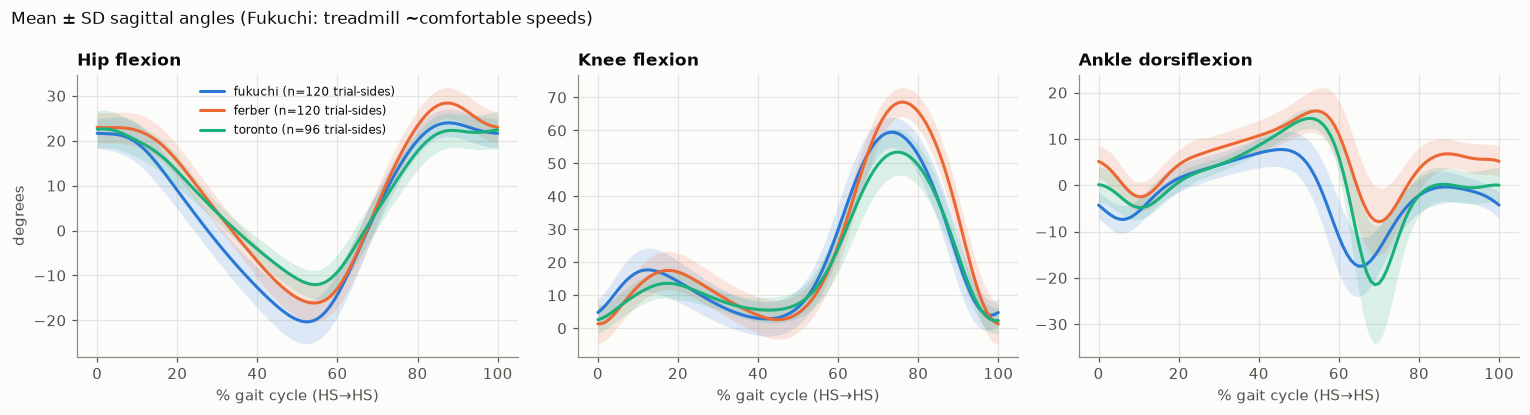

In [2]:
def mean_curves(ds, trials_, max_trials=60, seed=0):
    out = {k: [] for k in [f"{s}_{j}" for s in SIDES for j in ("hip", "knee", "ankle")]}
    for tr in pd.Series(trials_).sample(min(max_trials, len(trials_)), random_state=seed):
        c = cycle_curves(load_npz(ds, tr))
        for k, v in c.items():
            if len(v): out[k].append(v.mean(0))
    return {k: np.array(v) for k, v in out.items()}

sel = {"fukuchi": trials("fukuchi", True).query("mode == 'treadmill' and speed_label in ['T04','T05','T06']").trial,
       "ferber": trials("ferber", True).trial,
       "toronto": trials("toronto", True).trial}
MC = {d: mean_curves(d, t) for d, t in sel.items()}
x = np.linspace(0, 100, 101)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for a, j in zip(axs, ["hip", "knee", "ankle"]):
    for d in DATASETS:
        c = np.concatenate([MC[d][f"L_{j}"], MC[d][f"R_{j}"]])
        m, sd = c.mean(0), c.std(0)
        a.fill_between(x, m - sd, m + sd, color=COL[d], alpha=0.15, lw=0)
        a.plot(x, m, color=COL[d], label=f"{d} (n={len(c)} trial-sides)")
    a.set_title(j.capitalize() + (" flexion" if j != "ankle" else " dorsiflexion")); a.set_xlabel("% gait cycle (HS→HS)")
axs[0].set_ylabel("degrees"); axs[0].legend(fontsize=8)
fig.suptitle("Mean ± SD sagittal angles (Fukuchi: treadmill ~comfortable speeds)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "04_mean_cycles"); plt.show()

## Validation: our 2D knee/hip vs Fukuchi's 3D Visual3D angles
The dataset ships subject-mean gait-cycle angles (`*ang.txt`, 101 points, Z = flexion axis).
If the canonical mapping + projection is right, our curves should overlay theirs (modulo offset).

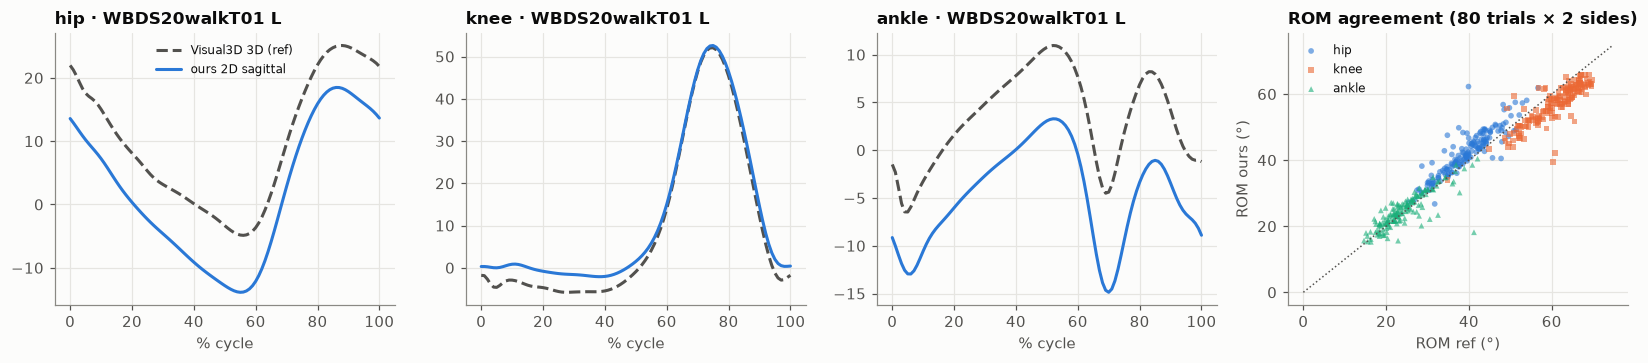

,r,rmse_centered,rom_ref,rom_ours
joint,,,,
ankle,0.97,1.79,23.16,24.08
hip,0.99,2.10,39.54,42.26
knee,0.99,3.40,61.98,58.20


In [3]:
import load_fukuchi as LF
FT = trials("fukuchi", True).query("mode == 'treadmill'")
rows, ex = [], None
for tr in FT.trial.sample(80, random_state=1):
    ref = pd.read_csv(LF.ASCII / f"{tr}ang.txt", sep="\t")
    ours = cycle_curves(load_npz("fukuchi", tr))
    for s in SIDES:
        for j, col in [("knee", "KneeAngleZ"), ("hip", "HipAngleZ"), ("ankle", "AnkleAngleZ")]:
            r = ref[f"{s}{col}"].to_numpy(); o = ours[f"{s}_{j}"].mean(0)
            rows.append(dict(trial=tr, side=s, joint=j, r=np.corrcoef(r, o)[0, 1],
                             rmse_centered=np.sqrt(np.mean(((o - o.mean()) - (r - r.mean())) ** 2)),
                             rom_ref=np.ptp(r), rom_ours=np.ptp(o)))
            if ex is None and j == "knee": ex = (tr, s)
V = pd.DataFrame(rows)
tr, s = ex
ref = pd.read_csv(LF.ASCII / f"{tr}ang.txt", sep="\t"); ours = cycle_curves(load_npz("fukuchi", tr))
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
for a, (j, col) in zip(axs, [("hip", "HipAngleZ"), ("knee", "KneeAngleZ"), ("ankle", "AnkleAngleZ")]):
    a.plot(x, ref[f"{s}{col}"], color=INK2, ls="--", label="Visual3D 3D (ref)")
    a.plot(x, ours[f"{s}_{j}"].mean(0), color=SERIES[0], label="ours 2D sagittal")
    a.set_title(f"{j} · {tr} {s}"); a.set_xlabel("% cycle")
axs[0].legend(fontsize=8)
for j, mk in zip(["hip", "knee", "ankle"], ["o", "s", "^"]):
    g = V[V.joint == j]
    axs[3].scatter(g.rom_ref, g.rom_ours, s=14, alpha=0.6, marker=mk, label=j, edgecolor="none")
lim = [0, max(V.rom_ref.max(), V.rom_ours.max()) + 5]
axs[3].plot(lim, lim, color=INK2, lw=1, ls=":"); axs[3].set_xlabel("ROM ref (°)"); axs[3].set_ylabel("ROM ours (°)")
axs[3].set_title("ROM agreement (80 trials × 2 sides)"); axs[3].legend(fontsize=8)
fig.tight_layout(); save(fig, "04_validation_vs_visual3d"); plt.show()
V.groupby("joint")[["r", "rmse_centered", "rom_ref", "rom_ours"]].median().round(2)

## Knee angle vs walking speed (Fukuchi, gold events)

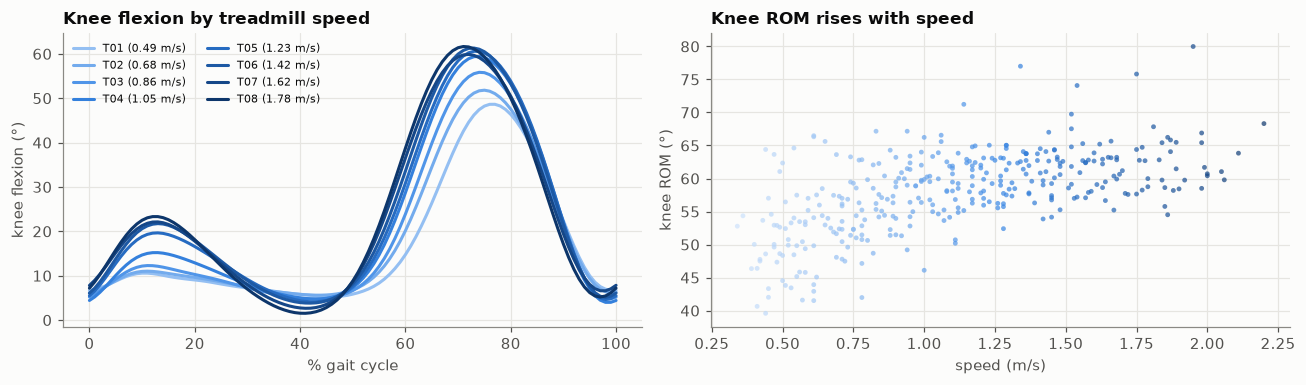

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
sp = FT.groupby("speed_label").speed.mean()
cm = SEQ_CMAP
for i, lab in enumerate(sorted(FT.speed_label.unique())):
    trs = FT[FT.speed_label == lab].trial
    c = mean_curves("fukuchi", trs, max_trials=25)
    k = np.concatenate([c["L_knee"], c["R_knee"]]).mean(0)
    axs[0].plot(x, k, color=cm(0.2 + 0.8 * i / 7), label=f"{lab} ({sp[lab]:.2f} m/s)")
axs[0].set_xlabel("% gait cycle"); axs[0].set_ylabel("knee flexion (°)"); axs[0].set_title("Knee flexion by treadmill speed")
axs[0].legend(fontsize=7, ncol=2)
axs[1].scatter(FT.speed, FT.knee_rom, s=10, c=FT.speed, cmap=cm, alpha=0.7, edgecolor="none")
axs[1].set_xlabel("speed (m/s)"); axs[1].set_ylabel("knee ROM (°)"); axs[1].set_title("Knee ROM rises with speed")
fig.tight_layout(); save(fig, "04_knee_by_speed"); plt.show()

## ROM distributions per dataset & subgroup check by age and sex

/tmp/nix-shell.SqEfpj/ipykernel_42712/223233202.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = a.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False)
/tmp/nix-shell.SqEfpj/ipykernel_42712/223233202.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = a.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False)
/tmp/nix-shell.SqEfpj/ipykernel_42712/223233202.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = a.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False)


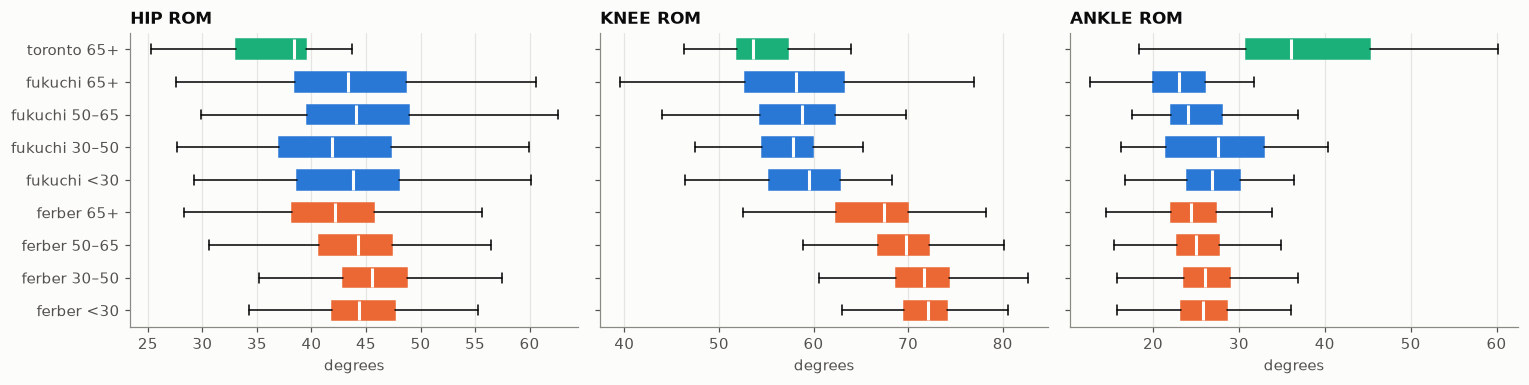

hip_rom  knee_rom  ankle_rom  peak_knee_flex
dataset sex1                                              
ferber  F        44.7      70.6       26.3            69.7
        M        45.2      71.4       24.8            70.3
        U        41.4      74.5       33.3            70.6
fukuchi F        44.8      60.5       26.5            60.1
        M        42.1      57.2       24.8            58.8
toronto F        38.1      53.5       35.7            55.8
        M        39.6      54.1       51.3            58.6

In [5]:
K = all_trials()
K = K[K["mode"] != "overground"].copy()
K["sex1"] = K.sex.astype(str).str.upper().str[0]
K["age_band"] = pd.cut(K.age, [0, 30, 50, 65, 120], labels=["<30", "30–50", "50–65", "65+"])
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for a, c in zip(axs, ["hip_rom", "knee_rom", "ankle_rom"]):
    g = K.groupby(["dataset", "age_band"], observed=True)[c]
    labels, data, colors = [], [], []
    for (d, ab), v in g:
        labels.append(f"{d} {ab}"); data.append(v.dropna()); colors.append(COL[d])
    bp = a.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False)
    for b, col in zip(bp["boxes"], colors): b.set(facecolor=col, color=col)
    for m in bp["medians"]: m.set(color=SURFACE, lw=2)
    a.set_yticks(range(1, len(labels) + 1), labels); a.set_title(c.replace("_", " ").upper()); a.set_xlabel("degrees")
    a.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "04_rom_by_age"); plt.show()
K.groupby(["dataset", "sex1"])[["hip_rom", "knee_rom", "ankle_rom", "peak_knee_flex"]].median().round(1)